# ch06_2. PyTorch ONNX 내보내기와 Runtime 추론

## 개요

- PyTorch Model(파이토치 모델), ONNX Model(오닉스 모델), ONNX Runtime을 구분합니다.
- `ONNXProgram`(오닉스 프로그램, 변환된 ONNX 모델 객체)을 파일로 저장합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [ ]:
# ONNX 변환과 실행에 필요한 패키지 설치 : 설치 또는 최신 버전으로 업그레이드
%pip install -U onnx onnxscript onnxruntime

# 우분투 터미널(컨트롤 + 알트 + t) 인 경우에는
# 설치 또는 최신 버전으로 업그레이드
#python -m pip install -U onnx onnxscript onnxruntime

Note: you may need to restart the kernel to use updated packages.


In [11]:
# ONNX 관련 패키지 설치 확인
import onnx
import onnxscript
import onnxruntime

print("ONNX       :", onnx.__version__)
print("ONNXScript :", onnxscript.__version__)
print("ONNXRuntime:", onnxruntime.__version__)

ONNX       : 1.22.0
ONNXScript : 0.7.1
ONNXRuntime: 1.29.0


In [12]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [13]:
from pathlib import Path
from urllib.request import urlretrieve
import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
import torch
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights

### 1) 전체 흐름

```text
사전학습 ResNet18 준비
→ 실제 이미지 전처리
→ PyTorch 기준 출력 생성
→ ONNX 변환
→ ONNX 파일 저장
→ 모델 구조 검사
→ ONNX Runtime Session 생성
→ NumPy 입력으로 추론
→ PyTorch 출력과 비교
→ Top-5 결과 비교
```

```text
.pth 또는 .pt
→ PyTorch Runtime
→ PC 직접 추론

.onnx
→ ONNX Runtime
→ PyTorch와 분리된 추론
```

| 구분 | 역할 |
|---|---|
| PyTorch Model | Python에서 정의하고 학습한 신경망 |
| ONNX Exporter(오닉스 익스포터) | PyTorch 계산 그래프를 ONNX로 변환 |
| ONNX Model | 계산 그래프와 가중치를 저장한 교환 형식 |
| ONNX Runtime | ONNX 모델을 읽고 추론하는 실행 엔진 |
| Execution Provider(이그제큐션 프로바이더) | CPU·GPU·NPU 등 실제 실행 장치와 연결 |

```text
PyTorch Model
→ ONNX Exporter
→ model.onnx
→ ONNX Runtime
→ CPU·GPU·가속기
```

ONNX 파일을 생성했다고 해서 자동으로 추론되는 것은 아닙니다. ONNX 파일을 읽고 실행하는 Runtime이 필요합니다.

코랩에서는 다음 세 패키지만 준비하면 됩니다.

```text
onnx
→ ONNX 파일 읽기와 구조 검사

onnxscript
→ 현재 PyTorch ONNX 변환 지원

onnxruntime
→ ONNX 모델 추론
```

CPU 실습에서는 `onnxruntime`을 사용합니다. GPU 실행은 환경에 맞는 별도 ONNX Runtime GPU 패키지가 필요하므로 이번 기본 실습에서는 다루지 않습니다.

### 2) 실행 장치와 버전 확인

변환과 결과 비교를 단순하게 하기 위해 PyTorch와 ONNX Runtime 모두 CPU를 사용합니다.

```text
PyTorch 기준 추론
→ CPU

ONNX 변환
→ CPU

ONNX Runtime 추론
→ CPUExecutionProvider
```

In [14]:
device = torch.device("cpu")

print("PyTorch 버전     :", torch.__version__)

print("ONNX 버전        :", onnx.__version__)

print("ONNX Runtime 버전:", ort.__version__)

print("실행 장치        :", device)

PyTorch 버전     : 2.13.0+cu130
ONNX 버전        : 1.22.0
ONNX Runtime 버전: 1.29.0
실행 장치        : cpu


### 3) 모델과 예시 이미지 준비

ImageNet(이미지넷, 대규모 이미지 분류 데이터셋)으로 사전학습된 ResNet18을 사용합니다.

```text
ResNet18_Weights.DEFAULT
→ 사전학습 가중치
→ 권장 전처리
→ ImageNet 1,000개 클래스 이름
```

입력 전처리 흐름:

```text
PIL Image
→ Resize·Center Crop
→ Tensor 변환
→ Normalize
→ [3, 224, 224]
→ Batch 차원 추가
→ [1, 3, 224, 224]
```

모델 기준      : ImageNet pretrained
모델           : ResNet
클래스 수      : 1000
원본 이미지 크기: (1546, 1213)
입력 Shape     : (1, 3, 224, 224)
입력 Dtype     : torch.float32


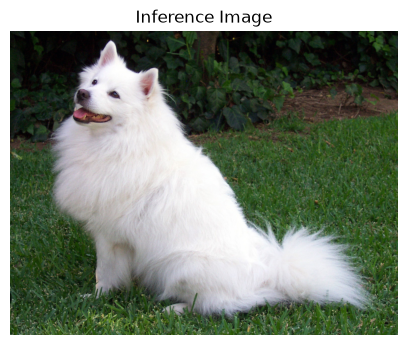

In [15]:
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
class_names = list(weights.meta["categories"])

try:
    model = resnet18(weights=weights).to(device).eval()
    model_source = "ImageNet pretrained"
except Exception:
    model = resnet18(weights=None).to(device).eval()
    model_source = "random initialized"
    print("사전학습 가중치를 받을 수 없어 미학습 ResNet18을 사용합니다.")

image_url = "https://github.com/pytorch/hub/raw/master/images/dog.jpg"
image_path = PNG_DIR / "dog.jpg"

try:
    if not image_path.exists():
        urlretrieve(image_url, image_path)
    image = Image.open(image_path).convert("RGB")
except Exception:
    image = Image.new("RGB", (224, 224), color=(128, 128, 128))
    print("예제 이미지를 받을 수 없어 회색 테스트 이미지를 사용합니다.")

input_tensor = preprocess(image).unsqueeze(0).to(device)

print("모델 기준      :", model_source)
print("모델           :", model.__class__.__name__)
print("클래스 수      :", len(class_names))
print("원본 이미지 크기:", image.size)
print("입력 Shape     :", tuple(input_tensor.shape))
print("입력 Dtype     :", input_tensor.dtype)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Inference Image")
plt.show()


### 4) PyTorch 기준 추론

변환 전 PyTorch 출력은 ONNX 결과를 판단하는 기준입니다.

\[
\mathbf{y}_{PT}=f_{\theta}(\mathbf{x})
\]

- $\mathbf{x}$: 전처리된 입력 이미지
- $f_{\theta}$: 학습된 가중치 $\theta$를 가진 ResNet18
- $\mathbf{y}_{PT}$: PyTorch가 출력한 Logit(로짓, 확률 변환 전 점수)

같은 입력을 ONNX Runtime에도 넣은 뒤 두 Logit을 비교합니다.

In [16]:
with torch.inference_mode():
    pytorch_logits = model(input_tensor)
    pytorch_probabilities = torch.softmax(pytorch_logits, dim=1)

print("PyTorch 출력 Shape:", tuple(pytorch_logits.shape))

print("PyTorch Top-1 Index:", int(pytorch_logits.argmax(dim=1).item()))

PyTorch 출력 Shape: (1, 1000)
PyTorch Top-1 Index: 258


### 5) ONNX 모델 내보내기

현재 PyTorch에서는 `torch.export` 기반 ONNX Exporter를 사용합니다.

```python
onnx_program = torch.onnx.export(
 model,
 (input_tensor,),
 input_names=["input"],
 output_names=["logits"],
 dynamo=True,
)
```

- `model`: 변환할 PyTorch 모델
- `(input_tensor,)`: 모델 구조를 분석할 Example Input(이그잼플 인풋, 예제 입력)
- `input_names`: ONNX 입력 이름
- `output_names`: ONNX 출력 이름
- `dynamo=True`: 현재 권장되는 `torch.export` 기반 변환 방식

현재 버전에서는 `dynamo=True`가 기본값이지만, 학습 목적상 명시적으로 적습니다.

In [17]:
onnx_path = MODEL_DIR / "resnet18_imagenet.onnx"

onnx_program = torch.onnx.export(
    model,
    (input_tensor,),
    input_names=["input"],
    output_names=["logits"],
    dynamo=True,
)

onnx_program.save(
    onnx_path,
    external_data=False,
)

print("ONNX 파일:", onnx_path)

print(f"파일 크기: {onnx_path.stat().st_size / 1024**2:.2f} MB")

[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX 파일: models/resnet18_imagenet.onnx
파일 크기: 44.66 MB


### 6) ONNX 모델 검사

ONNX 파일 생성 후에는 두 단계를 확인합니다.

```text
구조 검사
onnx.checker.check_model()

실행 정보 확인
InferenceSession.get_inputs()
InferenceSession.get_outputs()
InferenceSession.get_providers()
```

구조 검사를 통과했다는 것은 ONNX 그래프가 형식적으로 올바르다는 뜻입니다. PyTorch와 같은 값을 출력하는지는 별도로 비교해야 합니다.

In [18]:
onnx_model = onnx.load(onnx_path)

onnx.checker.check_model(onnx_model)

session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"],
)

session_input = session.get_inputs()[0]

session_output = session.get_outputs()[0]

opset_version = onnx_model.opset_import[0].version

print("ONNX 구조 검사: 통과")

print("Node 수        :", len(onnx_model.graph.node))

print("Opset 버전     :", opset_version)

print("사용 Provider  :", session.get_providers())

print("입력 이름·Shape :", session_input.name, session_input.shape)

print("출력 이름·Shape :", session_output.name, session_output.shape)

ONNX 구조 검사: 통과
Node 수        : 49
Opset 버전     : 20
사용 Provider  : ['CPUExecutionProvider']
입력 이름·Shape : input [1, 3, 224, 224]
출력 이름·Shape : logits [1, 1000]


### 7) ONNX Runtime 추론

ONNX Runtime의 Python API는 NumPy(넘파이, 수치 배열 라이브러리) 배열을 입력으로 받습니다.

```text
PyTorch Tensor
→ CPU로 이동
→ NumPy 배열 변환
→ float32 확인
→ ONNX Runtime 입력
```

\[
\mathbf{y}_{ORT}=g_{\theta}(\mathbf{x})
\]

- $g_{\theta}$: ONNX Runtime이 실행하는 변환 모델
- $\mathbf{y}_{ORT}$: ONNX Runtime 출력

In [19]:
input_array = input_tensor.detach().cpu().numpy().astype(np.float32)

onnx_logits = session.run(
    None,
    {session_input.name: input_array},
)[0]

print("ONNX 출력 Type :", type(onnx_logits))

print("ONNX 출력 Shape:", onnx_logits.shape)

print("ONNX Top-1 Index:", int(onnx_logits.argmax(axis=1)[0]))

ONNX 출력 Type : <class 'numpy.ndarray'>
ONNX 출력 Shape: (1, 1000)
ONNX Top-1 Index: 258


### 8) PyTorch·ONNX 출력 비교

최대 절대 오차:

\[
E_{\max}
=
\max_i
\left|
y_{PT,i}-y_{ORT,i}
\right|
\]

평균 절대 오차:

\[
E_{\mathrm{mean}}
=
\frac{1}{C}
\sum_{i=1}^{C}
\left|
y_{PT,i}-y_{ORT,i}
\right|
\]

- $C$: 전체 클래스 수
- 값이 작을수록 두 Runtime의 출력이 가깝습니다.
- 부동소수점 연산 순서가 달라 매우 작은 오차는 발생할 수 있습니다.

In [20]:
pytorch_output = pytorch_logits.detach().cpu().numpy()

absolute_error = np.abs(pytorch_output - onnx_logits)

max_error = absolute_error.max()

mean_error = absolute_error.mean()

np.testing.assert_allclose(
    pytorch_output,
    onnx_logits,
    rtol=1e-4,
    atol=1e-5,
)

print(f"최대 절대 오차: {max_error:.8f}")

print(f"평균 절대 오차: {mean_error:.8f}")

print("PyTorch ↔ ONNX 출력 검증: 통과")

최대 절대 오차: 0.00001526
평균 절대 오차: 0.00000193
PyTorch ↔ ONNX 출력 검증: 통과


### 9) Top-5 결과 비교

분류 모델의 Logit을 Softmax(소프트맥스, 여러 클래스 점수를 확률로 변환하는 함수)로 변환합니다.

\[
p_i
=
\frac{e^{z_i}}
{\sum_{j=1}^{C}e^{z_j}}
\]

PyTorch와 ONNX Runtime의 Top-5 클래스 순서와 확률을 비교합니다.

In [21]:
def print_top5(title, logits, class_names):
    probabilities = torch.softmax(torch.as_tensor(logits), dim=1)
    top_probs, top_indices = probabilities.topk(5, dim=1)

    print(title)
    for rank, (probability, class_index) in enumerate(
        zip(top_probs[0], top_indices[0]),
        start=1,
    ):
        index = int(class_index)
        print(
            f"{rank}. {class_names[index]:25s}"
            f" - {float(probability) * 100:6.2f}%"
        )

    return top_indices

pytorch_top5 = print_top5(
    "===== PyTorch Top-5 =====",
    pytorch_logits.detach().cpu(),
    class_names,
)

print()

onnx_top5 = print_top5(
    "===== ONNX Runtime Top-5 =====",
    onnx_logits,
    class_names,
)

print()

print("Top-5 순서 일치:", torch.equal(pytorch_top5, onnx_top5))

===== PyTorch Top-5 =====
1. Samoyed                   -  88.46%
2. Arctic fox                -   4.58%
3. white wolf                -   4.43%
4. Pomeranian                -   0.56%
5. Great Pyrenees            -   0.47%

===== ONNX Runtime Top-5 =====
1. Samoyed                   -  88.46%
2. Arctic fox                -   4.58%
3. white wolf                -   4.43%
4. Pomeranian                -   0.56%
5. Great Pyrenees            -   0.47%

Top-5 순서 일치: True
